# Long Short-Term Memory (LSTM)


<div style="font-size: 25px; color: #ff6600; font-weight: bold">
1. Libraries and settings
</div>


In this notebook, we will build and train an LSTM model to predict the stock market.

In [1]:
# Import libraries 

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.autograd import Variable
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

seed = 42
np.random.seed(seed)
torch.manual_seed(seed)

<div style="font-size: 25px; color: #ff6600; font-weight: bold">
2. Load data
</div>


In [2]:
# Read data 
df = pd.read_csv('NVDA.csv')

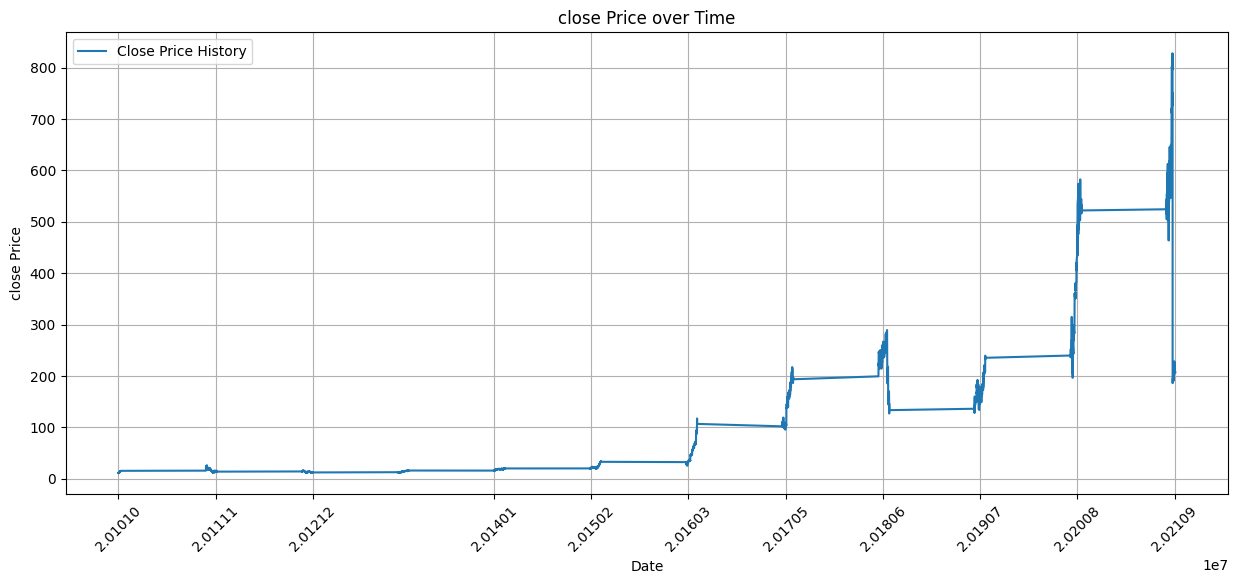

In [3]:
# Plot close prices ("<CLOSE>") based on dates ("<DATE>") 



plt.figure(figsize=(15, 6))
plt.plot(df["<DATE>"], df["<CLOSE>"], label='Close Price History')
plt.title(f'close Price over Time')
plt.xlabel('Date')
plt.ylabel(f'close Price')
plt.xticks(df["<DATE>"][::len(df)//10], rotation=45)
plt.legend()
plt.grid(True)
plt.show()


scaler = MinMaxScaler(feature_range=(0, 1))

df = df.drop(['<TICKER>', '<PER>'], axis=1)

# Keep dates separate from numerical features
dates = df['<DATE>'].copy()
features = df.drop(columns=['<DATE>'])

# Chronological split: first 80% for training, last 20% for testing
split_idx = int(len(features) * 0.8)

train_features = features.iloc[:split_idx]
test_features = features.iloc[split_idx:]

# Fit only on training data
train_scaled = scaler.fit_transform(train_features)

# Transform test data using the training-fitted scaler
test_scaled = scaler.transform(test_features)

# Recombine in chronological order
df = pd.DataFrame(
    np.vstack([train_scaled, test_scaled]),
    columns=features.columns
)


#####################

In [4]:
# function to create train, test data given stock data and sequence length
def load_data(stock, look_back):
    data_raw = stock.values # convert to numpy array
    data = []
    
    # create all possible sequences of length look_back
    for index in range(len(data_raw) - look_back): 
        data.append(data_raw[index: index + look_back])
    
    data = np.array(data)
    test_set_size = int(np.round(0.2*data.shape[0]))
    train_set_size = data.shape[0] - (test_set_size)
    
    x_train = data[:train_set_size,:-1,:]
    y_train = data[:train_set_size,-1,:]
    
    x_test = data[train_set_size:,:-1]
    y_test = data[train_set_size:,-1,:]
    
    return [x_train, y_train, x_test, y_test]

look_back = 60 # choose sequence length
x_train, y_train, x_test, y_test = load_data(df, look_back)
print('x_train.shape = ',x_train.shape)
print('y_train.shape = ',y_train.shape)
print('x_test.shape = ',x_test.shape)
print('y_test.shape = ',y_test.shape)

x_train.shape =  (2166, 59, 6)
y_train.shape =  (2166, 6)
x_test.shape =  (541, 59, 6)
y_test.shape =  (541, 6)


<div style="font-size: 25px; color: #ff6600; font-weight: bold">
3. Build the structure of models
</div>


In [5]:
# Build model

input_dim = df.shape[1]
hidden_dim = 32
num_layers = 2
output_dim = 1


class LSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_layers, output_dim):
        super(LSTM, self).__init__()
        # Hidden dimensions
        self.hidden_dim = hidden_dim

        # Number of hidden layers
        self.num_layers = num_layers

        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True)

        # Readout layer
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
       
        h0 = torch.zeros(self.num_layers, x.shape[0], self.hidden_dim)
        c0 = torch.zeros(self.num_layers, x.shape[0], self.hidden_dim)
        out, (hn, cn) = self.lstm(x, (h0, c0))
        out = self.fc(out[:, -1, :]) 
        
        return out
        


In [6]:
# Train models

close_index = list(df.columns).index('<CLOSE>')
y_train = y_train[:, close_index].reshape(-1, 1)
y_test  = y_test[:, close_index].reshape(-1, 1)

x_train = torch.from_numpy(x_train).float()
x_test = torch.from_numpy(x_test).float()
y_train = torch.from_numpy(y_train).float()
y_test = torch.from_numpy(y_test).float()
model = LSTM(input_dim=input_dim, hidden_dim=hidden_dim, num_layers=num_layers, output_dim=output_dim)

num_epochs = 500
learning_rate = 0.005

criterion = torch.nn.MSELoss(reduction='mean')
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

hist = np.zeros(num_epochs)

for t in range(num_epochs):

    model.train()
    optimizer.zero_grad() 

    y_pred = model(x_train)

    loss = criterion(y_pred, y_train)
    hist[t] = loss.item()

    
    loss.backward()       
    optimizer.step()      

    if (t+1) % 10 == 0:
        print(f"Epoch [{t+1}/{num_epochs}] Loss: {loss.item():.7f}")

Epoch [10/500] Loss: 0.0039171
Epoch [20/500] Loss: 0.0017758
Epoch [30/500] Loss: 0.0008111
Epoch [40/500] Loss: 0.0006434
Epoch [50/500] Loss: 0.0004678
Epoch [60/500] Loss: 0.0003269
Epoch [70/500] Loss: 0.0002767
Epoch [80/500] Loss: 0.0002599
Epoch [90/500] Loss: 0.0002472
Epoch [100/500] Loss: 0.0002359
Epoch [110/500] Loss: 0.0002258
Epoch [120/500] Loss: 0.0002168
Epoch [130/500] Loss: 0.0002086
Epoch [140/500] Loss: 0.0002011
Epoch [150/500] Loss: 0.0001944
Epoch [160/500] Loss: 0.0001883
Epoch [170/500] Loss: 0.0001827
Epoch [180/500] Loss: 0.0001776
Epoch [190/500] Loss: 0.0001729
Epoch [200/500] Loss: 0.0001687
Epoch [210/500] Loss: 0.0001647
Epoch [220/500] Loss: 0.0001612
Epoch [230/500] Loss: 0.0001579
Epoch [240/500] Loss: 0.0001550
Epoch [250/500] Loss: 0.0001523
Epoch [260/500] Loss: 0.0001499
Epoch [270/500] Loss: 0.0001477
Epoch [280/500] Loss: 0.0001458
Epoch [290/500] Loss: 0.0002299
Epoch [300/500] Loss: 0.0001633
Epoch [310/500] Loss: 0.0001508
Epoch [320/500] L

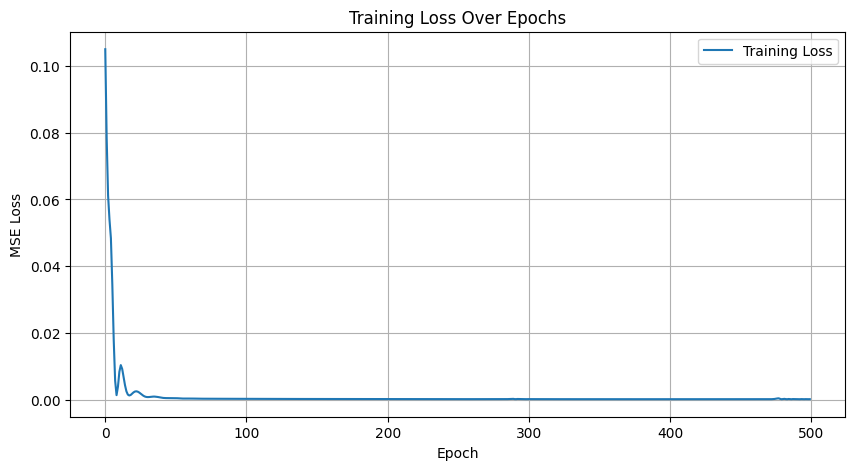

In [7]:
# Plot loss based on epochs

plt.figure(figsize=(10, 5))
plt.plot(hist, label="Training Loss")
plt.title("Training Loss Over Epochs")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.show()

In [8]:

model.eval()


with torch.no_grad():
    y_train_pred = model(x_train)
    y_test_pred = model(x_test)

close_index = list(df.columns).index('<CLOSE>')


scale_close = scaler.scale_[close_index]
min_close = scaler.min_[close_index]

y_train_pred_original = (y_train_pred - min_close) / scale_close
y_test_pred_original  = (y_test_pred - min_close) / scale_close
y_train_original      = (y_train - min_close) / scale_close
y_test_original       = (y_test - min_close) / scale_close


train_rmse = np.sqrt(mean_squared_error(y_train_original, y_train_pred_original))
test_rmse = np.sqrt(mean_squared_error(y_test_original, y_test_pred_original))

print(f'Train RMSE: {train_rmse:.4f}')
print(f'Test RMSE: {test_rmse:.4f}')

Train RMSE: 3.1135
Test RMSE: 72.2960


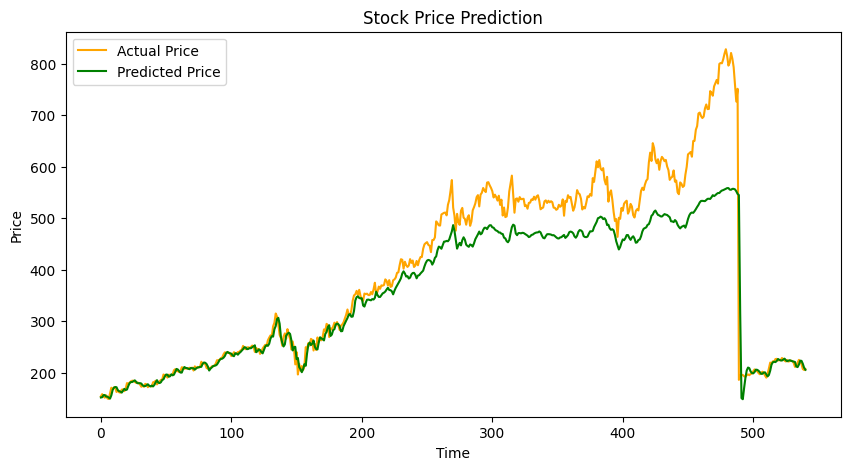

In [9]:
# Visualising the prediction results

plt.figure(figsize=(10,5))
plt.plot(y_test_original, label='Actual Price', color='orange')
plt.plot(y_test_pred_original, label='Predicted Price', color='green')
plt.title("Stock Price Prediction")
plt.xlabel("Time")
plt.ylabel("Price")
plt.legend()
plt.show()

<div  style="font-size: 17px; line-height: 150%">
    <div style="font-size: 25px; color: #ff6600; font-weight: bold">
       4. Comparison of Model Prediction Performance
    </div>
      In this section, we will compare the prediction performance of the provided LSTM model with that of pre-built models. The goal is to evaluate how well the given implementation captures the underlying patterns in the data compared to standard implementations.
</div>

Epoch 1/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - loss: 0.0616 - val_loss: 0.0346
Epoch 2/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 258ms/step - loss: 0.0076 - val_loss: 0.0776
Epoch 3/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 261ms/step - loss: 0.0145 - val_loss: 0.0156
Epoch 4/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 267ms/step - loss: 0.0018 - val_loss: 0.0040
Epoch 5/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 264ms/step - loss: 0.0028 - val_loss: 0.0120
Epoch 6/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 269ms/step - loss: 0.0070 - val_loss: 0.0116
Epoch 7/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 257ms/step - loss: 0.0069 - val_loss: 0.0052
Epoch 8/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 263ms/step - loss: 0.0038 - val_loss: 0.0028
Epoch 9/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 267ms/step - loss: 0.0011 - val_loss: 0.0092
Epoch 10/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 289ms/step - loss: 9.0792e-04 - val_loss: 0.0200
Epoch 11/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 256ms/step - loss: 0.0026 - val_loss: 0.0248
Epoch 12/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 267ms/step - loss: 0.

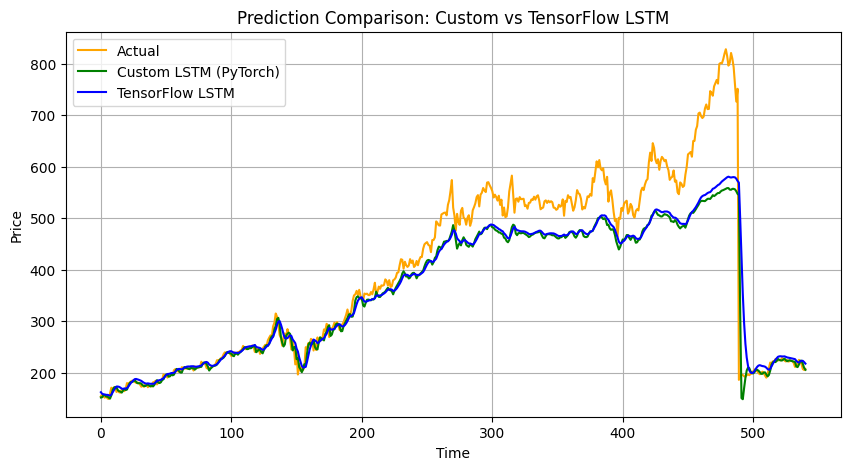

In [10]:
from tensorflow.keras import Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import  Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import LSTM as Prebuilt_LSTM


x_train_tf = x_train
x_test_tf = x_test
y_train_tf = y_train
y_test_tf = y_test


tf_model = Sequential([
    Input(shape=(x_train_tf.shape[1], x_train_tf.shape[2])),
    Prebuilt_LSTM(hidden_dim, return_sequences=(num_layers > 1))
])

for i in range(1, num_layers):
    return_seq = (i != num_layers - 1)
    tf_model.add(Prebuilt_LSTM(hidden_dim, return_sequences=return_seq))

tf_model.add(Dense(output_dim))


tf_model.compile(optimizer=Adam(learning_rate=learning_rate), loss='mse')


history = tf_model.fit(
    x_train_tf, y_train_tf,
    epochs=num_epochs,
    batch_size=len(x_train_tf),
    validation_split=0.1,
    verbose=1
)

y_test_pred_tf = tf_model.predict(x_test_tf)

y_test_pred_tf_orig = (y_test_pred_tf - min_close) / scale_close
y_test_orig_tf = (y_test_tf - min_close) / scale_close


rmse_tf = np.sqrt(mean_squared_error(y_test_orig_tf, y_test_pred_tf_orig))
print(f"TensorFlow LSTM RMSE: {rmse_tf:.4f}")


plt.figure(figsize=(10,5))
plt.plot(y_test_original, label='Actual', color='orange')
plt.plot(y_test_pred_original, label='Custom LSTM (PyTorch)', color='green')
plt.plot(y_test_pred_tf_orig, label='TensorFlow LSTM', color='blue')
plt.title("Prediction Comparison: Custom vs TensorFlow LSTM")
plt.xlabel("Time")
plt.ylabel("Price")
plt.legend()
plt.grid(True)
plt.show()


 Use denoising techniques and train models again after denoising the prices.

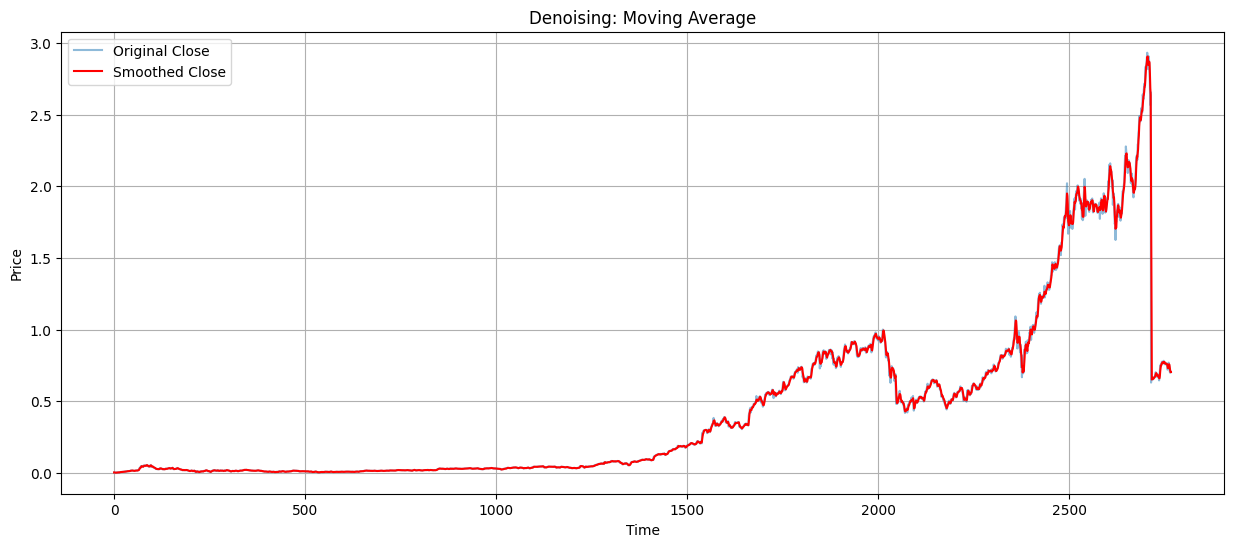

Epoch [10/500] Loss: 0.0071348
Epoch [20/500] Loss: 0.0013734
Epoch [30/500] Loss: 0.0017466
Epoch [40/500] Loss: 0.0007356
Epoch [50/500] Loss: 0.0003909
Epoch [60/500] Loss: 0.0004101
Epoch [70/500] Loss: 0.0003167
Epoch [80/500] Loss: 0.0002971
Epoch [90/500] Loss: 0.0002703
Epoch [100/500] Loss: 0.0002486
Epoch [110/500] Loss: 0.0002305
Epoch [120/500] Loss: 0.0002134
Epoch [130/500] Loss: 0.0001971
Epoch [140/500] Loss: 0.0001817
Epoch [150/500] Loss: 0.0001680
Epoch [160/500] Loss: 0.0001565
Epoch [170/500] Loss: 0.0001476
Epoch [180/500] Loss: 0.0001410
Epoch [190/500] Loss: 0.0001358
Epoch [200/500] Loss: 0.0001307
Epoch [210/500] Loss: 0.0001255
Epoch [220/500] Loss: 0.0001203
Epoch [230/500] Loss: 0.0001151
Epoch [240/500] Loss: 0.0001099
Epoch [250/500] Loss: 0.0001048
Epoch [260/500] Loss: 0.0000998
Epoch [270/500] Loss: 0.0000950
Epoch [280/500] Loss: 0.0000903
Epoch [290/500] Loss: 0.0000859
Epoch [300/500] Loss: 0.0000817
Epoch [310/500] Loss: 0.0000777
Epoch [320/500] L

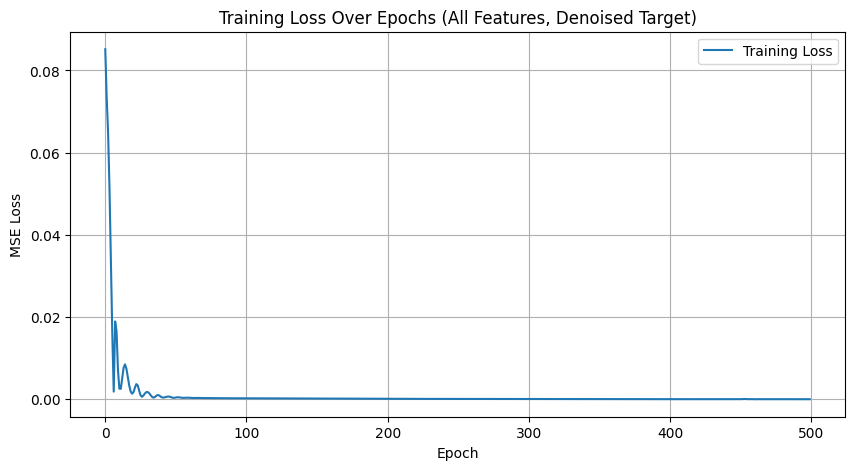

Train RMSE: 3.5467
Test RMSE: 71.3712


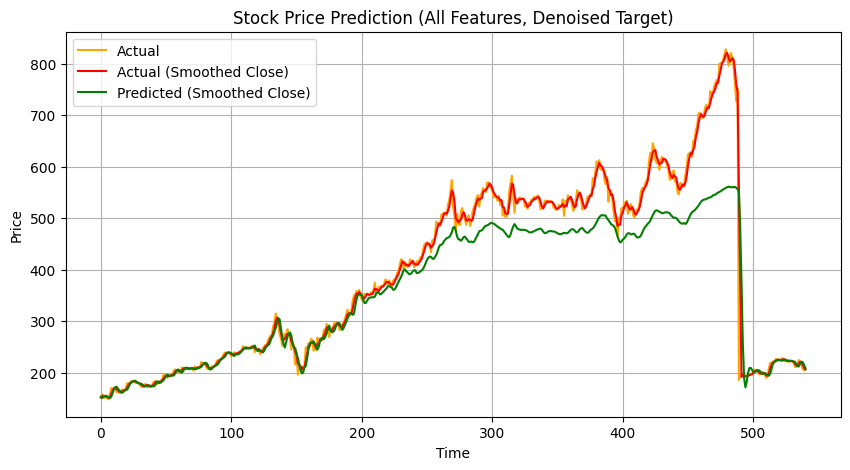

In [11]:

df['Close_Smooth'] = df['<CLOSE>'].rolling(window=3, min_periods=1).mean()

plt.figure(figsize=(15,6))
plt.plot(df['<CLOSE>'], label='Original Close', alpha=0.5)
plt.plot(df['Close_Smooth'], label='Smoothed Close', color='red')
plt.title("Denoising: Moving Average")
plt.xlabel("Time")
plt.ylabel("Price")
plt.legend()
plt.grid(True)
plt.show()

df = df.drop(columns=['<CLOSE>'])
target_col = 'Close_Smooth'

x_train, y_train, x_test, y_test = load_data(df, look_back)

close_index = list(df.columns).index(target_col)
y_train = y_train[:, close_index].reshape(-1, 1)
y_test  = y_test[:, close_index].reshape(-1, 1)


x_train_tensors = torch.from_numpy(x_train).float()
x_test_tensors = torch.from_numpy(x_test).float()
y_train_tensors = torch.from_numpy(y_train).float()
y_test_tensors = torch.from_numpy(y_test).float()


model = LSTM(input_dim, hidden_dim, num_layers, output_dim)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

hist = np.zeros(num_epochs)

for t in range(num_epochs):
    model.train()
    optimizer.zero_grad() 

    y_pred = model(x_train_tensors)
    loss = criterion(y_pred, y_train_tensors)
    hist[t] = loss.item()

    loss.backward()
    optimizer.step()

    if (t+1) % 10 == 0:
        print(f"Epoch [{t+1}/{num_epochs}] Loss: {loss.item():.7f}")


plt.figure(figsize=(10,5))
plt.plot(hist, label='Training Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Training Loss Over Epochs (All Features, Denoised Target)')
plt.legend()
plt.grid(True)
plt.show()


model.eval()
with torch.no_grad():
    y_train_pred = model(x_train_tensors).cpu().numpy()
    y_test_pred = model(x_test_tensors).cpu().numpy()



y_train_pred_orig = (y_train_pred - min_close) / scale_close
y_test_pred_orig  = (y_test_pred - min_close) / scale_close
y_train_orig      = (y_train_tensors.cpu().numpy() - min_close) / scale_close
y_test_orig       = (y_test_tensors.cpu().numpy() - min_close) / scale_close


train_rmse = np.sqrt(mean_squared_error(y_train_original, y_train_pred_orig))
test_rmse = np.sqrt(mean_squared_error(y_test_original, y_test_pred_orig))
print(f'Train RMSE: {train_rmse:.4f}')
print(f'Test RMSE: {test_rmse:.4f}')

plt.figure(figsize=(10,5))
plt.plot(y_test_original, label='Actual', color='orange')
plt.plot(y_test_orig, label='Actual (Smoothed Close)', color='red')
plt.plot(y_test_pred_orig, label='Predicted (Smoothed Close)', color='green')
plt.plot ()
plt.title("Stock Price Prediction (All Features, Denoised Target)")
plt.xlabel("Time")
plt.ylabel("Price")
plt.legend()
plt.grid(True)
plt.show()
